# Lab 11: Attention


### Attention is a mechanism that allows a neural network to focus more on relevant information when making a prediction.

Encoder-decoder architecture with attention:
<img src="https://drive.google.com/thumbnail?id=1-QeHdZIeKTo_nAqfh7pRA_o4Nk8CAmP6&sz=w1000" width="700">

## Step 1 — Import libraries

In [2]:
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

## Step 2 — Upload the dataset

In [3]:
df = pd.read_csv("dataset/Lab_11_QnA_Dataset.csv")
print("Number of questions:", len(df))
print("Number of answer groups:", df["answer_id"].nunique())
display(df.head())

Number of questions: 168
Number of answer groups: 12


,question,answer_id,answer
0,Do you get hurt?,0,I don't have a body.
1,Do you have fingers?,0,I don't have a body.
2,Do you ever breathe,0,I don't have a body.
3,Do you masticate?,0,I don't have a body.
4,Can you throw up?,0,I don't have a body.


## Step 3 — Preprocessing

1. Lowercase each question and remove punctuation.
2. Give each word a number.
3. Make all questions the same length by adding zeros (**padding**).

In [4]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. Lowercase
df["question"] = df["question"].str.lower()

# 2. Tokenization
tokenizer = Tokenizer()
tokenizer.fit_on_texts(df["question"])

# Convert words to numbers and add padding
X = pad_sequences(tokenizer.texts_to_sequences(df["question"]), padding="post")

# Answers
y = df["answer_id"].values

# Convert to PyTorch tensors
X = torch.tensor(X, dtype=torch.long)
y = torch.tensor(y, dtype=torch.long)

## Step 4 — Build an RNN with attention

- **Embedding** turns word numbers into vectors.
- **RNN** reads the words in sequence.
- **Attention** gives each word a weight.
- **Output** chooses one answer from the dataset.

In [5]:
class RNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(tokenizer.word_index) + 1, 16)
        self.rnn = nn.RNN(16, 32, batch_first=True)  # fixed: input is (batch, words), not (words, batch)
        self.att = nn.Linear(32, 1)
        self.fc = nn.Linear(32, df["answer_id"].nunique())

    def forward(self, x):
        x, _ = self.rnn(self.emb(x))
        weights = torch.softmax(self.att(x), dim=1)
        return self.fc((x * weights).sum(1)), weights.squeeze(-1)

model = RNN()

## Step 5 — Train the model
The model learns which answer belongs to each question.

In [6]:
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

for epoch in range(50):
    optimizer.zero_grad() #fixed: clear the gradients from the previous epoch
    loss = nn.functional.cross_entropy(model(X)[0], y) #calculate loss to reduce it
    loss.backward() #backpropagation to update parameters
    optimizer.step() #update parameters

print("Training finished!")

Training finished!


## Step 6 — See attention
The bar chart shows how much attention the model gives to each question word.

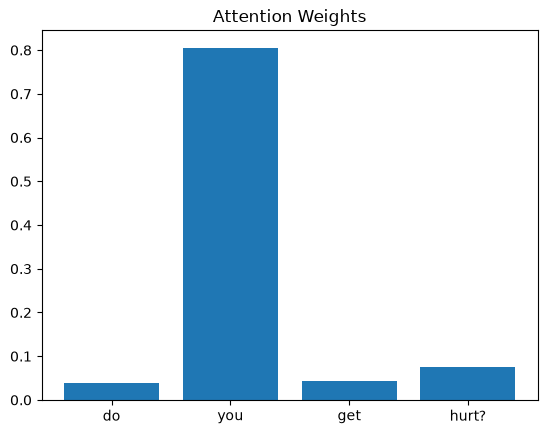

In [7]:
question = df["question"][0]
words = question.split()

with torch.no_grad():
    prediction, weights = model(X[:1])

plt.bar(words, weights[0, :len(words)].tolist())
plt.title("Attention Weights")
plt.show()

## Tasks:


Task 1 — Understand Attention Weights
Easy

Modify Step 6 to visualize the attention weights for three different questions from the dataset instead of only the first question.

Instructions:
- Select three questions from the dataset.
- Generate an attention bar chart for each question.
- Identify the word receiving the highest attention weight in each question.

Question: Do the words with the highest attention weights appear important for understanding the question? Explain your observations.

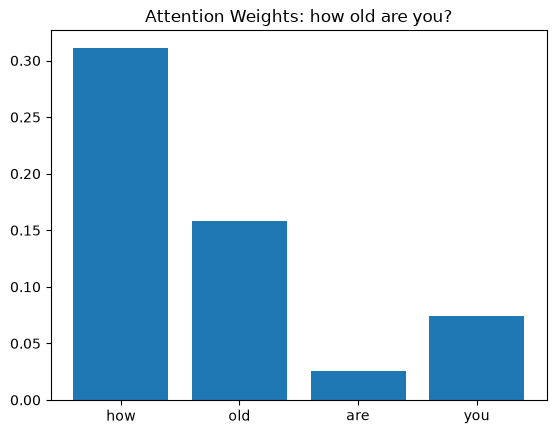

Question: how old are you?
Highest attention: 'how' (0.311)
Predicted answer group: 1 (correct: 1)



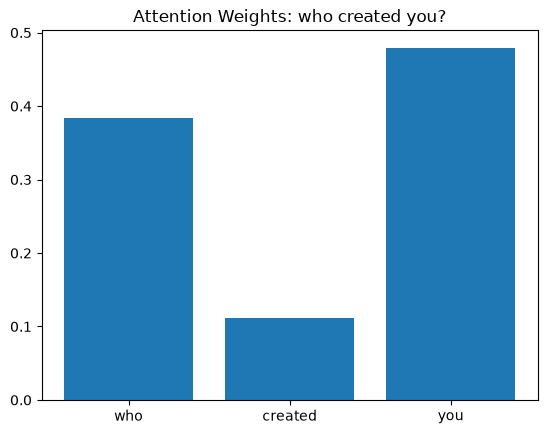

Question: who created you?
Highest attention: 'you' (0.479)
Predicted answer group: 3 (correct: 3)



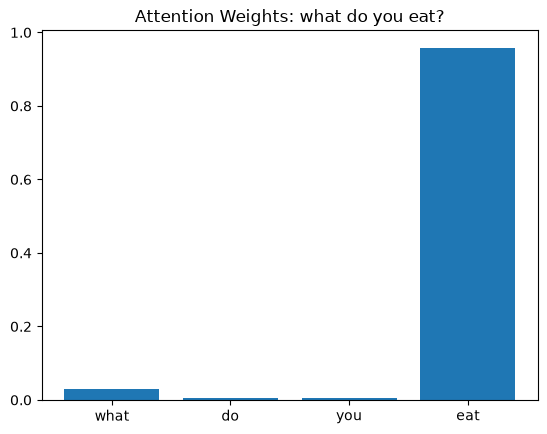

Question: what do you eat?
Highest attention: 'eat' (0.958)
Predicted answer group: 7 (correct: 7)



In [8]:
def show_attention(index):
    """Plot the attention weights for one question and return its highest-attention word."""
    with torch.no_grad():
        prediction, weights = model(X[index:index + 1])

    # Use the tokenizer's words so the labels always line up with the weights
    tokens = [tokenizer.index_word[i] for i in X[index].tolist() if i != 0]
    attention = weights[0, :len(tokens)].tolist()
    top_word = tokens[attention.index(max(attention))]

    plt.bar(range(len(tokens)), attention)
    plt.xticks(range(len(tokens)), tokens)
    plt.title(f"Attention Weights: {df['question'][index]}")
    plt.show()

    predicted = prediction.argmax(1).item()
    print(f"Question: {df['question'][index]}")
    print(f"Highest attention: '{top_word}' ({max(attention):.3f})")
    print(f"Predicted answer group: {predicted} (correct: {y[index].item()})\n")
    return top_word

for index in [24, 48, 108]:  # "How old are you?", "Who created you?", "What do you eat?"
    show_attention(index)

**Answer:**

| Question | Highest attention | Weight | Second highest |
|---|---|---|---|
| how old are you? | how | 0.311 | old (about 0.16) |
| who created you? | you | 0.479 | who (about 0.38) |
| what do you eat? | eat | 0.958 | |

Sometimes, but not always. In "what do you eat?", the top word "eat" is the most important word. In "how old are you?", the important word "old" is only second. In "who created you?", the top word is "you", which is in most questions, and "created" gets only about 0.11.

The model only learns which words help it pick one of the 12 answer groups, so it may not choose the words a person would choose. Also, an RNN remembers earlier words, so a high weight on a later word like "you" can include the words before it.

The weights for "how old are you?" add up to only about 0.57 because the rest of the attention went to the padding zeros. On average across the dataset, this is small (about 3%).

Task 2 — Compare Attention for Similar Questions
Medium

Select two questions from the dataset that have similar meanings but different wording.

Instructions:
- Pass both questions through the trained model.
- Visualize their attention weights.
- Compare the words receiving the highest attention weights.

Question: Does the model focus on similar or different words when processing questions with similar meanings? What does this suggest about how attention works?

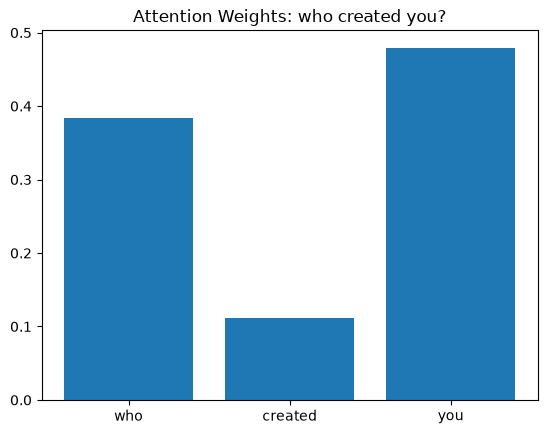

Question: who created you?
Highest attention: 'you' (0.479)
Predicted answer group: 3 (correct: 3)



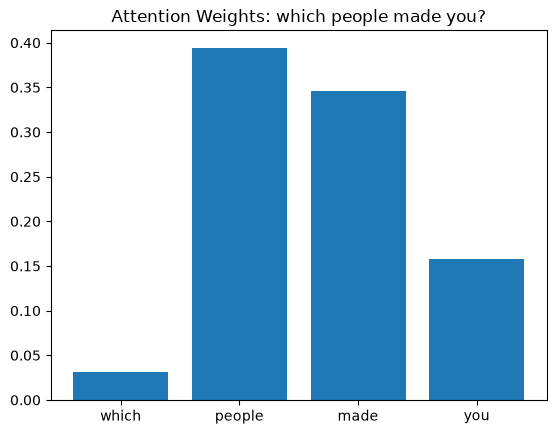

Question: which people made you?
Highest attention: 'people' (0.394)
Predicted answer group: 3 (correct: 3)



In [9]:
# "Who created you?" and "Which people made you?" ask the same thing in different words
for index in [48, 54]:
    show_attention(index)

**Answer:** I compared "who created you?" and "which people made you?". The model gives the correct answer group for both (group 3, "People created me.").

- **who created you?**: "you" is highest (0.479), then "who" (about 0.38), then "created" (about 0.11).
- **which people made you?**: "people" is highest (0.394), then "made" (about 0.35), then "you" (about 0.16), then "which" (about 0.03).

The model focuses on different words, even though the two questions mean the same thing. This suggests that attention depends on the exact words in the question and where they are, not directly on the meaning. The model can reach the same answer by focusing on different words.